# USD/VND – exploratory analysis and model evaluation

This notebook documents the analysis behind the Streamlit app:

1. Data quality: raw Yahoo `VND=X` quotes vs the cleaned series
2. Statistical properties of daily log-returns (stationarity, autocorrelation, volatility clustering)
3. Walk-forward backtest of random walk, ARIMA and gradient boosting

All functions come from `src/`, so the notebook and the app use identical code.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # run from notebooks/

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats

from src.data_loader import load_fx_data
from src.backtest import summarize
from src.models import ARIMAForecaster, GBMForecaster

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})
data = load_fx_data("snapshot")
y = data.series
print(data.label, "|", len(y), "business days |", data.n_cleaned, "quotes cleaned")

Yahoo Finance VND=X, bundled snapshot (to 23 Oct 2026) | 3082 business days | 157 quotes cleaned


## 1. Data quality
The raw feed shows one-day spikes that fully revert. They are removed before modelling; persistent moves are kept.

,raw,cleaned
daily std (bp),45.8658,20.0618
excess kurtosis,11.0684,10.8545


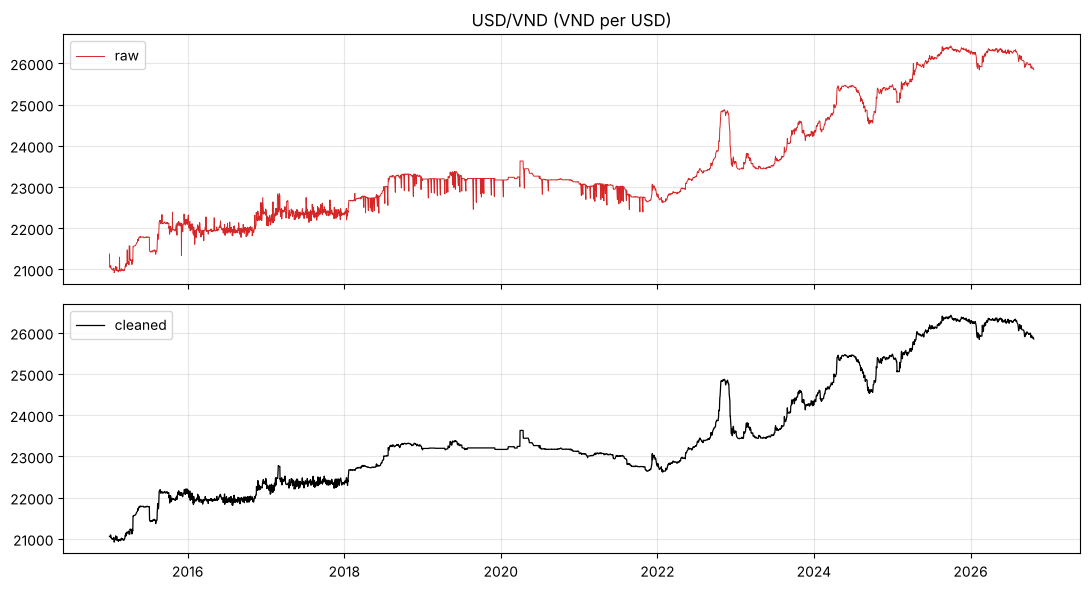

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(data.raw, color="tab:red", lw=0.7, label="raw"); ax[0].legend()
ax[1].plot(y, color="k", lw=0.9, label="cleaned"); ax[1].legend()
ax[0].set_title("USD/VND (VND per USD)"); plt.tight_layout()

r_raw = np.log(data.raw).diff().dropna()
r = np.log(y).diff().dropna()
pd.DataFrame({"raw": [r_raw.std()*1e4, stats.kurtosis(r_raw)], "cleaned": [r.std()*1e4, stats.kurtosis(r)]},
             index=["daily std (bp)", "excess kurtosis"])

## 2. Properties of daily log-returns
Unit-root tests on log levels and returns (ADF: H0 unit root; KPSS: H0 stationary).

In [3]:
def unit_root(x):
    adf_p = adfuller(x, autolag="AIC")[1]
    kpss_p = kpss(x, regression="c", nlags="auto")[1]
    return pd.Series({"ADF p-value": adf_p, "KPSS p-value": kpss_p})

import warnings; warnings.filterwarnings("ignore")  # KPSS p-values are truncated to [0.01, 0.1]
pd.DataFrame({"log level": unit_root(np.log(y)), "log return": unit_root(r)})

,log level,log return
ADF p-value,0.6131,3.7142e-17
KPSS p-value,0.0100,1.0000e-01


Autocorrelation of returns (Ljung–Box) and of squared returns (ARCH-LM). Significant ARCH effects mean volatility clusters, which matters for interval width.

,lb_stat,lb_pvalue
1,5.3642,0.0206
5,13.3396,0.0204
10,30.0022,0.0009


ARCH-LM(5) on last 3y: stat = 48.8, p = 0.0000


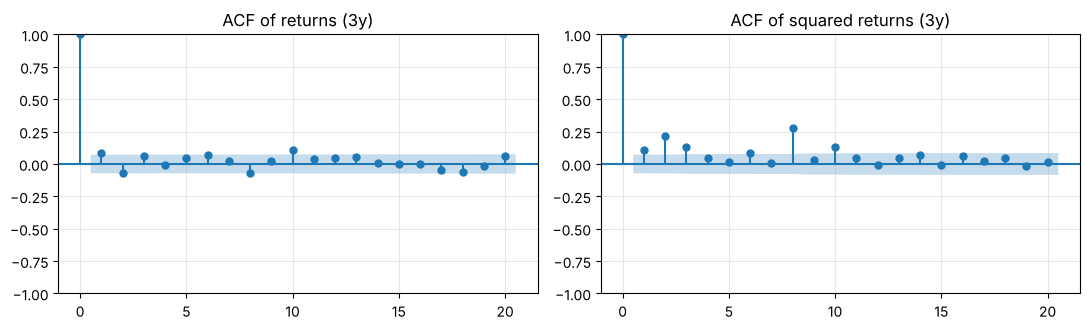

In [4]:
recent = r.iloc[-756:]   # last 3 years, the default training window
lb = acorr_ljungbox(recent, lags=[1, 5, 10], return_df=True)
arch_lm, arch_p, _, _ = het_arch(recent, nlags=5)
display(lb)
print(f"ARCH-LM(5) on last 3y: stat = {arch_lm:.1f}, p = {arch_p:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plot_acf(recent, lags=20, ax=ax[0], title="ACF of returns (3y)")
plot_acf(recent**2, lags=20, ax=ax[1], title="ACF of squared returns (3y)"); plt.tight_layout()

Text(0.5, 0, '')

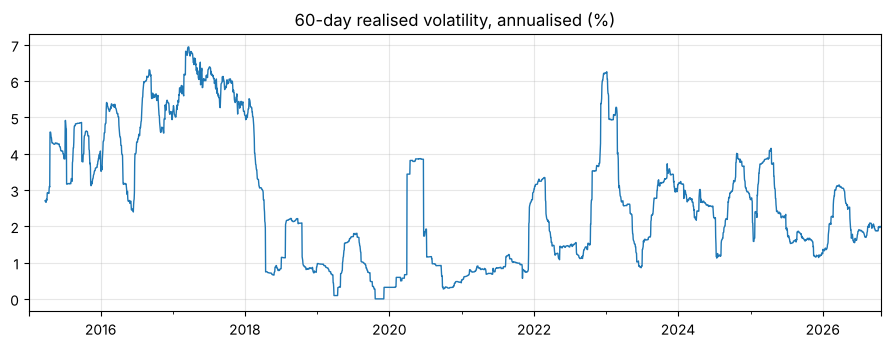

In [5]:
ann_vol = r.rolling(60).std() * np.sqrt(252) * 100
ax = ann_vol.plot(color="tab:blue", lw=1, title="60-day realised volatility, annualised (%)"); ax.set_xlabel("")

## 3. Models fitted on the latest 3-year window

In [6]:
window = y.iloc[-756:]
arima = ARIMAForecaster().fit(window)
gbm = GBMForecaster().fit(window)
print(arima.describe()); print(gbm.describe())
print(arima.result_.summary().tables[1])

ARIMA(1,1,2), AIC = -7,620
Gradient boosting, hold-out RMSE = 12.6 bp/day
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6201      0.168     -3.688      0.000      -0.950      -0.291
ma.L1          0.7230      0.169      4.286      0.000       0.392       1.054
ma.L2         -0.0121      0.038     -0.317      0.751      -0.087       0.063
sigma2      2.385e-06    6.6e-08     36.144      0.000    2.26e-06    2.51e-06


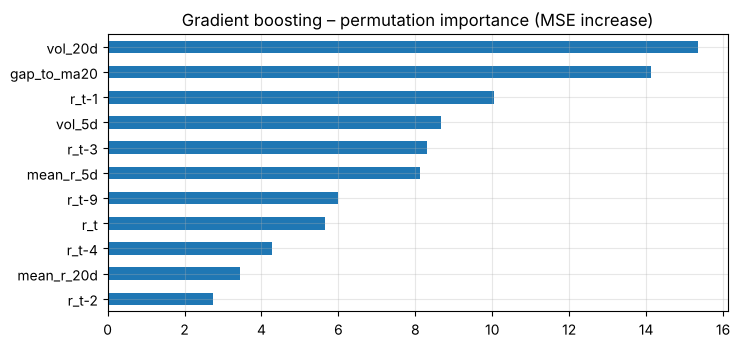

In [7]:
imp = gbm.feature_importance()
ax = imp.sort_values().plot.barh(title="Gradient boosting – permutation importance (MSE increase)", figsize=(8, 3.6))

## 4. Walk-forward backtest
Precomputed by `python -m scripts.refresh_data` (40 origins, 7 business days apart, 3-year rolling window, horizons 1–30).
Relative RMSE below 1 means better than the random walk. DM = Diebold–Mariano test (HLN-corrected) against the random walk.

In [8]:
import json
bt = pd.read_csv("../data/backtest_results.csv", parse_dates=["origin"])
meta = json.loads(pathlib.Path("../data/backtest_meta.json").read_text())
summ = summarize(bt, step=meta["step"])
print(meta)
summ[summ.h.isin([1, 5, 10, 14, 20, 30])].pivot(index="h", columns="model", values=["rel_RMSE", "DM_pvalue", "coverage"]).round(3)

{'train_size': 756, 'horizon': 30, 'n_origins': 40, 'step': 7, 'level': 0.9, 'data_end': '2026-10-23', 'first_origin': '2025-08-26', 'last_origin': '2026-09-11'}


rel_RMSE                               DM_pvalue                    \
model    ARIMA Gradient boosting Random walk     ARIMA Gradient boosting   
h                                                                          
1        1.017             1.132         1.0     0.665             0.133   
5        0.992             1.038         1.0     0.424             0.743   
10       0.997             1.188         1.0     0.681             0.275   
14       0.998             1.166         1.0     0.763             0.181   
20       0.999             1.224         1.0     0.807             0.131   
30       1.005             1.409         1.0     0.438             0.028   

                  coverage                                
model Random walk    ARIMA Gradient boosting Random walk  
h                                                         
1             NaN    0.975             0.875       0.900  
5             NaN    0.950             0.950       0.900  
10            NaN    0.975             0.975       0.925  
14            NaN    0.950             0.950       0.900  
20            NaN    0.975             0.925       0.875  
30            NaN    1.000             0.950       0.875

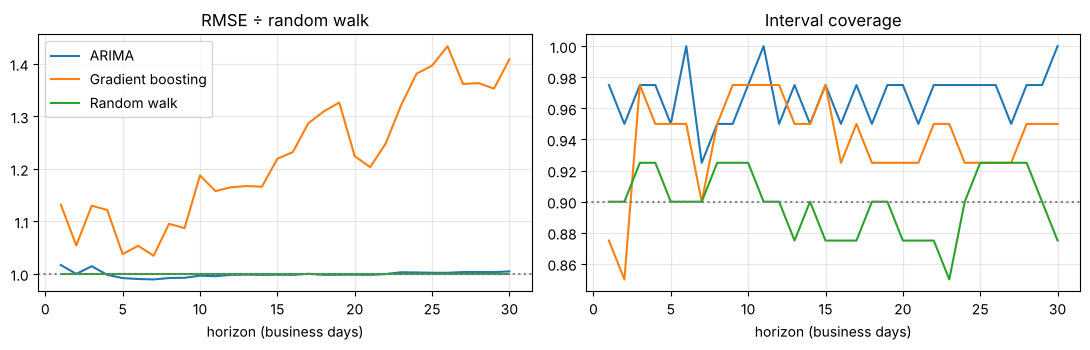

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for m, g in summ.groupby("model"):
    ax[0].plot(g.h, g.rel_RMSE, label=m); ax[1].plot(g.h, g.coverage, label=m)
ax[0].axhline(1, color="grey", ls=":"); ax[0].set_title("RMSE ÷ random walk"); ax[0].set_xlabel("horizon (business days)")
ax[1].axhline(meta["level"], color="grey", ls=":"); ax[1].set_title("Interval coverage"); ax[1].set_xlabel("horizon (business days)")
ax[0].legend(); plt.tight_layout()

## 5. Reading the results

The conclusions below refer to the outputs above (snapshot to the date shown in `meta`):

- **Returns look stationary, log levels do not** (ADF fails to reject a unit root in log levels; KPSS rejects stationarity of levels but not of returns). This supports modelling first differences.
- **Returns show weak but statistically significant autocorrelation in-sample** (Ljung–Box p < 0.05 at lags 1, 5, 10), yet the fitted ARIMA has nearly offsetting AR and MA terms, and **out-of-sample it is statistically indistinguishable from the random walk** at every horizon tested.
- **Gradient boosting is less accurate than the random walk at every horizon shown**, significantly so only at 30 days. Recursive forecasting appears to compound a small predicted drift into a trend that the test period did not reward.
- **Volatility clusters and tails are fat** (ARCH-LM p < 0.01; excess kurtosis ≈ 11). Bands that assume constant volatility are therefore likely to be too narrow in stress periods and too wide in calm ones. In this test period the random-walk band, based on the last 250 days of volatility, is closest to nominal coverage; ARIMA's band, estimated over three years, tends to be wider than needed.

These results are consistent with the long-standing difficulty of beating a random walk for exchange rates at short horizons (Meese and Rogoff, 1983). With 40 overlapping origins over roughly one year, the tests have limited power, and the ranking may change across regimes.